# Tutorial: Convolutional Neural Networks in PyTorch

In this tutorial you will see why an ordinary multilayer perceptron (MLP) struggles with images, and how a **convolutional neural network (CNN)** solves the problem with far fewer parameters.

The task: small, noisy images each contain one faint mark, either a **+** or a **×**, somewhere in the image. Which mark is it?

**Contents**

0. Setup
1. The data: images of '+' and '×' marks
2. Training, validation and test data
3. Training with mini-batches
4. An MLP on images
5. Building a CNN in PyTorch
6. Training the CNN
7. Comparing the MLP and the CNN
8. What did the CNN learn?

Cells marked **Example** can simply be run. Cells marked **Exercise** contain `# TODO` gaps for you to complete. Cells marked **Your evaluation** are for you to write your own comments and conclusions.

---
## 0. Setup

### Example 0

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
%matplotlib inline

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
print("PyTorch version:", torch.__version__)

PyTorch version: 2.15.0+cpu


---
## 1. The data: images of '+' and '×' marks

Each image is 24 × 24 pixels of random noise. Somewhere in it, at a random position, is one faint 5 × 5 mark:

- a **'+'** (label $y = 0$), or
- a **'×'** (label $y = 1$).

Both marks are made of exactly 9 bright pixels, so the overall brightness of the image gives nothing away: only the **shape** of the mark tells you the answer.

### Example 1

In [3]:
nw, K = 24, 5                                         # image size and mark size (pixels)

PLUS = np.zeros((K, K))
PLUS[K // 2, :] = 1                                  # horizontal stroke
PLUS[:, K // 2] = 1                                  # vertical stroke

CROSS = np.eye(K) + np.fliplr(np.eye(K))             # the two diagonals
CROSS[K // 2, K // 2] = 1                            # centre pixel counted once

def make_marks(n=800, noise=0.35, seed=0):
    """n noisy nw x nh images where nw = nh, each with one '+' (y = 0) or 'x' (y = 1) mark at a random position.
    Returns X with shape (n, nw, nh) and y with shape (n, 1), both float32 NumPy arrays."""
    rng = np.random.default_rng(seed)
    y = rng.random(n) < 0.5                          # True for 'x', False for '+'
    X = rng.normal(0, noise, (n, nw, nw))              # background noise
    for i in range(n):
        r, c = rng.integers(0, nw - K + 1, 2)         # random top-left corner of the mark
        X[i, r:r + K, c:c + K] += CROSS if y[i] else PLUS
    return X.astype(np.float32), y.astype(np.float32).reshape(-1, 1)

X, y = make_marks()
print("X shape:", X.shape, "  y shape:", y.shape, "  fraction of 'x' marks:", y.mean())

X shape: (800, 24, 24)   y shape: (800, 1)   fraction of 'x' marks: 0.47875


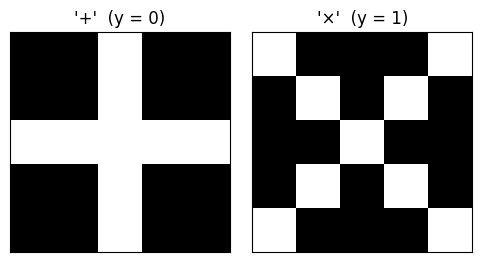

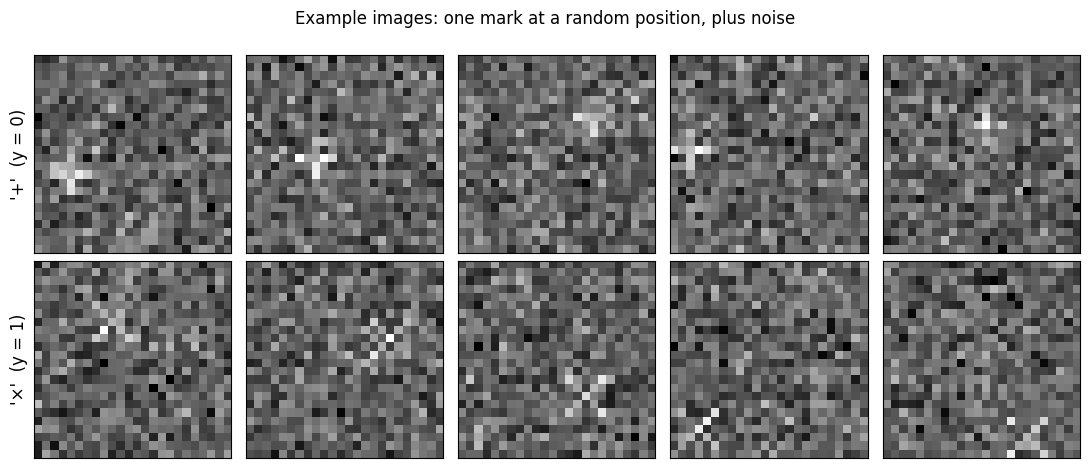

In [4]:
# The two marks on their own
fig, axs = plt.subplots(1, 2, figsize=(5, 2.6))
for ax, mark, name in [(axs[0], PLUS, "'+'  (y = 0)"), (axs[1], CROSS, "'×'  (y = 1)")]:
    ax.imshow(mark, cmap="gray"); ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

# Some example images: can you find the marks?
fig, axs = plt.subplots(2, 5, figsize=(11, 4.8))
for row, label in [(0, 0), (1, 1)]:
    for ax, i in zip(axs[row], np.where(y[:, 0] == label)[0][:5]):
        ax.imshow(X[i], cmap="gray", vmin=-1, vmax=1.6); ax.set_xticks([]); ax.set_yticks([])
    axs[row, 0].set_ylabel("'+'  (y = 0)" if label == 0 else "'×'  (y = 1)", fontsize=12)
plt.suptitle("Example images: one mark at a random position, plus noise"); plt.tight_layout(); plt.show()

---
## 2. Training, validation and test data

As in Tutorial 7, we shuffle and split the images: 60% training, 20% validation, 20% test.

PyTorch's image layers expect each image to have a **channel** dimension: colour images have 3 channels (red, green, blue), and our greyscale images have 1. So the data must have shape

$$(\text{number of images},\ \text{channels},\ \text{height},\ \text{width}) = (n, 1, 24, 24).$$

`X[:, None]` adds that extra dimension of size 1.
The height and width are the number of pixels across and down.

### Example 2

In [5]:
def split_data(X, y, frac_train=0.6, frac_val=0.2, seed=0):
    """Shuffle the examples, then split them into training, validation and test sets."""
    rng = np.random.default_rng(seed)
    n = len(X)
    idx = rng.permutation(n)
    n_train, n_val = int(frac_train * n), int(frac_val * n)
    train_idx, val_idx, test_idx = idx[:n_train], idx[n_train:n_train + n_val], idx[n_train + n_val:]
    return X[train_idx], y[train_idx], X[val_idx], y[val_idx], X[test_idx], y[test_idx]

X_train, y_train, X_val, y_val, X_test, y_test = split_data(X, y)

# Convert everything into PyTorch tensors, adding a channel dimension to the images (n, 1, nw, nh)
X_train_t = torch.tensor(X_train[:, None], dtype=torch.float32)    # (n, 1, 24, 24)
X_val_t = torch.tensor(X_val[:, None], dtype=torch.float32)
X_test_t = torch.tensor(X_test[:, None], dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)             # (n, 1)
y_val_t = torch.tensor(y_val, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

print("training images:", tuple(X_train_t.shape))
print("validation images:", tuple(X_val_t.shape))
print("test images:", tuple(X_test_t.shape))

training images: (480, 1, 24, 24)
validation images: (160, 1, 24, 24)
test images: (160, 1, 24, 24)


---
## 3. Training with mini-batches

In Tutorial 7 every update used all the training data at once (batch gradient descent). Here we use **mini-batches**: each epoch, the training images are shuffled and split into batches of 32, and the weights are updated once per batch. Each update is the same five steps as before, just on a batch instead of the whole training set.

At the end of each epoch we measure the cost and the accuracy on the **whole** training set and the **whole** validation set, using the current weights.

This is just setting up the training loop, we'll code up the models next.

### Exercise 3

In [6]:
def accuracy(model, X_t, y_t):
    """Fraction of images classified correctly (threshold 0.5)."""
    with torch.no_grad():
        y_pred = (model(X_t).numpy() >= 0.5).astype(np.float32)
    return np.mean(y_pred == y_t.numpy())

def train_model(model, optimiser, loss_fn, n_epochs, batch_size=32):
    """Mini-batch training. Uses the global tensors X_train_t, y_train_t, X_val_t, y_val_t.
    Returns lists of the training cost, validation cost, training accuracy and validation accuracy after each epoch."""
    J_train, J_val, acc_train, acc_val = [], [], [], []
    n = len(X_train_t)
    for epoch in range(n_epochs):
        perm = torch.randperm(n)                      # a new random order of the training images each epoch
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]      # the indices of the images in this mini-batch
            X_batch, y_batch = X_train_t[idx], y_train_t[idx]
            y_hat = model(X_batch)               # forward pass on the mini-batch
            J = loss_fn(y_hat, y_batch)          # cost on the mini-batch
            optimiser.zero_grad()                # clear the old gradients
            J.backward()                         # backprop from J
            optimiser.step()                     # update the weights and biases

        with torch.no_grad():                         # end of epoch: measure, don't train
            J_train.append(loss_fn(model(X_train_t), y_train_t).item())
            J_val.append(loss_fn(model(X_val_t), y_val_t).item())
        acc_train.append(accuracy(model, X_train_t, y_train_t))
        acc_val.append(accuracy(model, X_val_t, y_val_t))
    return J_train, J_val, acc_train, acc_val

### Example 3

In [7]:
def plot_curves(J_train, J_val, acc_train, acc_val, title=""):
    """Cost (left) and accuracy (right) on the training and validation sets, against epoch."""
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(J_train, color=BLUE, lw=2, label="training")
    axs[0].plot(J_val, color=ORANGE, lw=2, label="validation")
    axs[0].set_xlabel("epoch"); axs[0].set_ylabel("cost $J$"); axs[0].set_ylim(bottom=0); axs[0].legend()
    axs[1].plot(100 * np.array(acc_train), color=BLUE, lw=2, label="training")
    axs[1].plot(100 * np.array(acc_val), color=ORANGE, lw=2, label="validation")
    axs[1].axhline(50, color=GREY, ls=":", lw=1); axs[1].text(len(acc_val) - 1, 47, "guessing", ha="right", va="top", color=GREY)
    axs[1].set_xlabel("epoch"); axs[1].set_ylabel("accuracy (%)"); axs[1].set_ylim(30, 102); axs[1].legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()

def count_parameters(model):
    """Total number of weights and biases in the model."""
    return sum(p.numel() for p in model.parameters())

---
## 4. Trying an MLP on this dataset

An MLP needs a flat list of numbers as input, so the first layer, `nn.Flatten()`, turns each $1 \times 24 \times 24$ image into a list of $576$ pixel values. After that it is an ordinary MLP: 2 hidden layers of 64 ReLU neurons and a sigmoid output.

### Example 4

In [8]:
torch.manual_seed(0)
mlp = nn.Sequential(
    nn.Flatten(),                       # (n, 1, 24, 24) -> (n, 576)
    nn.Linear(576, 64), nn.ReLU(),       # hidden layer 1
    nn.Linear(64, 64), nn.ReLU(),        # hidden layer 2
    nn.Linear(64, 1), nn.Sigmoid())     # output layer
print(mlp)
print("Number of parameters:", count_parameters(mlp))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=576, out_features=64, bias=True)
  (2): ReLU()
  (3): Linear(in_features=64, out_features=64, bias=True)
  (4): ReLU()
  (5): Linear(in_features=64, out_features=1, bias=True)
  (6): Sigmoid()
)
Number of parameters: 41153


final training cost 0.000,  final validation cost 4.665
final training accuracy 1.000,  final validation accuracy 0.475


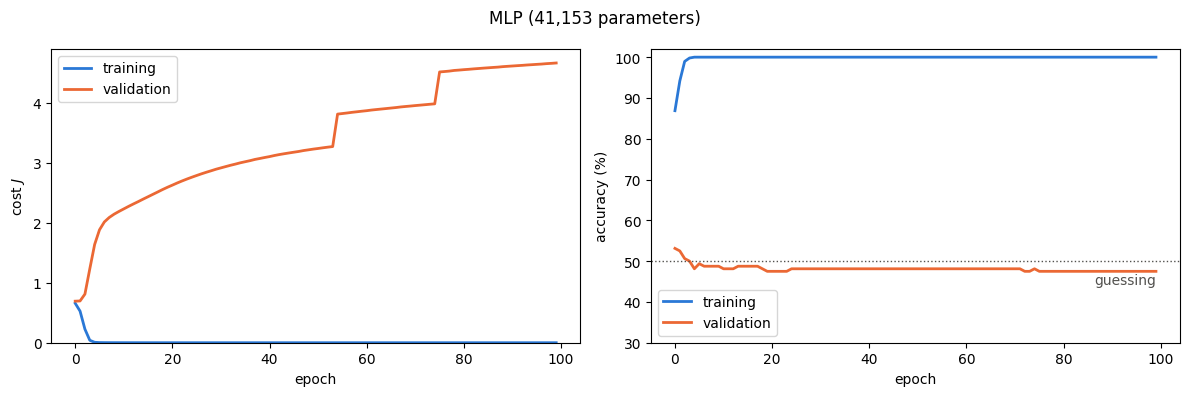

In [9]:
optimiser = torch.optim.Adam(mlp.parameters(), lr=0.002)
# TODO: fill in train_model footprint to train the model with 100 epochs 
J_train, J_val, acc_train, acc_val = train_model(mlp, optimiser, nn.BCELoss(), n_epochs=100)

print(f"final training cost {J_train[-1]:.3f},  final validation cost {J_val[-1]:.3f}")
print(f"final training accuracy {acc_train[-1]:.3f},  final validation accuracy {acc_val[-1]:.3f}")
plot_curves(J_train, J_val, acc_train, acc_val, f"MLP ({count_parameters(mlp):,} parameters)")

### Your evaluation 4

*The training cost looks excellent. What do the validation cost and validation accuracy tell you? Is this underfitting or overfitting? Why might an MLP find this task so hard? (Hint: think about which weights a '+' in the top-left corner uses, compared with a '+' in the bottom-right corner.)*

...

The MLP is badly overfitting. Training cost falls to about 0 and training accuracy reaches 100%, but validation cost climbs steadily to 4.7 and validation accuracy sits around 47.5%, which is no better than guessing. It has memorised the 480 training images without learning anything that transfers. Underfitting would show high error on both sets, and here the training error is near zero.

The task is hard for an MLP because every pixel has its own weight. A '+' in the top-left corner uses completely different weights from a '+' in the bottom-right, so nothing learned at one position carries over to another. With 41,153 parameters and only 480 images, the network can memorise the specific noise patterns, and the 20 or so possible positions of each mark are far too few examples to learn the shape separately at each one.

---
## 5. Building a CNN in PyTorch

A convolutional layer uses small **filters** (here 5 × 5) instead of one weight per pixel. Each filter is slid across every position in the image; at each position it multiplies the 25 pixels under it by its 25 (trainable) weights, adds them up and adds its bias, exactly like a single neuron. So a filter is one small neuron applied **everywhere**, with the same weights at every position.

### Example 5a: a convolutional layer

`nn.Conv2d(1, 8, kernel_size=5)` is a layer of **8 filters**, each of size 5 × 5, acting on images with 1 channel. Each filter produces its own output image (a **feature map**) showing how strongly the filter responds at each position. A 5 × 5 filter fits into a 24 × 24 image at $24 - 5 + 1 = 20$ positions in each direction, so each feature map is 20 × 20.

Here are the 8 feature maps for one image, with random (untrained) filters.

filter weights, shape (8, 1, 5, 5) = (filters, input channels, height, width)
biases, shape (8,) = one per filter
input shape: (1, 1, 24, 24)   output shape: (1, 8, 20, 20)


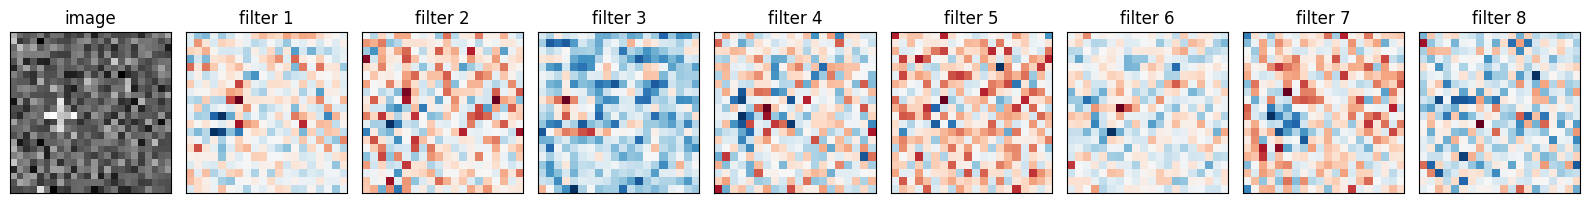

In [10]:
torch.manual_seed(0) # set the random number generator to a known state, so that the convolutional filters are the same each time
conv = nn.Conv2d(1, 8, kernel_size=5)        # 8 filters of 5 x 5, 1 input channel
print("filter weights, shape", tuple(conv.weight.shape), "= (filters, input channels, height, width)")
print("biases, shape", tuple(conv.bias.shape), "= one per filter")

one_image = X_train_t[:1]                    # shape (1, 1, 24, 24): a batch of one image
maps = conv(one_image)
print("input shape:", tuple(one_image.shape), "  output shape:", tuple(maps.shape))

fig, axs = plt.subplots(1, 9, figsize=(16, 2.4))
axs[0].imshow(one_image[0, 0].numpy(), cmap="gray"); axs[0].set_title("image")
for f in range(8):
    axs[f + 1].imshow(maps[0, f].detach().numpy(), cmap="RdBu_r"); axs[f + 1].set_title(f"filter {f + 1}")
for ax in axs: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

(`.detach()` is needed before `.numpy()` here because the maps were computed outside `torch.no_grad()`, so PyTorch is still recording them for backprop.)

### Example 5b: ReLU and global max pooling

After the convolution we apply ReLU to every value in the feature maps, as usual.

Then comes **pooling**. We only care *whether* a mark is present, not *where*, so for each filter we keep just its **largest response anywhere in the image**. This is called global max pooling: `nn.AdaptiveMaxPool2d(1)` shrinks each 20 × 20 feature map down to a single number. A filter that has learned to detect a '×' will give a large value if there is a '×' anywhere in the image.

That leaves 8 numbers per image, which `nn.Flatten()` turns into an ordinary list, ready for an output neuron.

In [11]:
relu = nn.ReLU()
pool = nn.AdaptiveMaxPool2d(1)               # each feature map -> its single largest value
flatten = nn.Flatten()

A = relu(maps)
P = pool(A)
F = flatten(P)
print("after ReLU:      ", tuple(A.shape))
print("after pooling:   ", tuple(P.shape))
print("after flattening:", tuple(F.shape))
print("the 8 numbers:", F.detach().numpy().round(3))

after ReLU:       (1, 8, 20, 20)
after pooling:    (1, 8, 1, 1)
after flattening: (1, 8)
the 8 numbers: [[0.797 0.752 0.894 0.582 0.482 1.058 0.595 0.913]]


### Example 5c: what `nn.AdaptiveMaxPool2d(1)` does

After the convolution and ReLU, each image has become 8 feature maps of 20 × 20: one map per filter, showing how strongly that filter responded at every position.

**Max pooling** shrinks a feature map by keeping only the largest value in each region:

- `nn.MaxPool2d(2)` uses a fixed 2 × 2 window, so each block of 4 values becomes 1 and the map halves in size (20 × 20 → 10 × 10). The positions are still there, just coarser.
- `nn.AdaptiveMaxPool2d(1)` works the other way round: you give it the **output size** you want, and it chooses the window for you. Asking for an output of 1 × 1 makes the window the whole map, so each 20 × 20 map becomes **one number: the filter's strongest response anywhere in the image**. This is called **global max pooling**.

Global max pooling suits this task because we only care **whether** a '+' or '×' is in the image, not **where**. A filter that has learned to detect a '×' gives a large value if there is a '×' anywhere, and the output neuron only needs one weight per filter, so a mark counts the same wherever it appears.

The cell below shows both kinds of pooling on two small 4 × 4 feature maps.

In [12]:
# Two small 4 x 4 feature maps (as if from 2 filters), shape (1 image, 2 maps, 4, 4)
maps_small = torch.tensor([[[[1, 3, 0, 2],
                             [5, 2, 1, 0],
                             [0, 1, 4, 6],
                             [2, 0, 3, 1]],

                            [[0, 0, 1, 0],
                             [0, 7, 0, 0],
                             [2, 0, 0, 1],
                             [0, 1, 0, 0]]]], dtype=torch.float32)

print("feature maps, shape", tuple(maps_small.shape))
print(maps_small[0])

pooled_2x2 = nn.MaxPool2d(2)(maps_small)                # largest value in each 2 x 2 block
print("\nnn.MaxPool2d(2): shape", tuple(pooled_2x2.shape), "- each map halves in size")
print(pooled_2x2[0])

pooled_global = nn.AdaptiveMaxPool2d(1)(maps_small)     # largest value in the whole map
print("\nnn.AdaptiveMaxPool2d(1): shape", tuple(pooled_global.shape), "- one number per map")
print(pooled_global[0])

print("\nafter nn.Flatten():", nn.Flatten()(pooled_global))   # (1, 2): ready for nn.Linear(2, 1)

feature maps, shape (1, 2, 4, 4)
tensor([[[1., 3., 0., 2.],
         [5., 2., 1., 0.],
         [0., 1., 4., 6.],
         [2., 0., 3., 1.]],

        [[0., 0., 1., 0.],
         [0., 7., 0., 0.],
         [2., 0., 0., 1.],
         [0., 1., 0., 0.]]])

nn.MaxPool2d(2): shape (1, 2, 2, 2) - each map halves in size
tensor([[[5., 2.],
         [2., 6.]],

        [[7., 1.],
         [2., 1.]]])

nn.AdaptiveMaxPool2d(1): shape (1, 2, 1, 1) - one number per map
tensor([[[6.]],

        [[7.]]])

after nn.Flatten(): tensor([[6., 7.]])


### Exercise 5

Build the full CNN as one `nn.Sequential`:

1. a convolutional layer with 8 filters of size 5 × 5 (1 input channel),
2. ReLU,
3. global max pooling,
4. flatten,
5. an output layer of 1 neuron with 8 inputs, and a sigmoid.

In [13]:
torch.manual_seed(0)
cnn = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=5),   # 8 filters of 5 x 5
    nn.ReLU(),
    nn.AdaptiveMaxPool2d(1),          # global max pooling
    nn.Flatten(),                     # (n, 8, 1, 1) -> (n, 8)
    nn.Linear(8, 1),                  # output layer
    nn.Sigmoid())

print(cnn)
print("Number of parameters:", count_parameters(cnn))

Sequential(
  (0): Conv2d(1, 8, kernel_size=(5, 5), stride=(1, 1))
  (1): ReLU()
  (2): AdaptiveMaxPool2d(output_size=1)
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)
Number of parameters: 217


In [14]:
# Check your answer (should print True)
with torch.no_grad():
    out = cnn(X_train_t)
print(count_parameters(cnn) == 8 * (5 * 5 + 1) + (8 + 1) and tuple(out.shape) == (len(X_train_t), 1))

True


---
## 6. Training the CNN

Exactly the same training as the MLP: Adam with $\alpha = 0.002$, mini-batches of 32, 100 epochs.

### Example 6

final training cost 0.002,  final validation cost 0.005
final training accuracy 1.000,  final validation accuracy 1.000


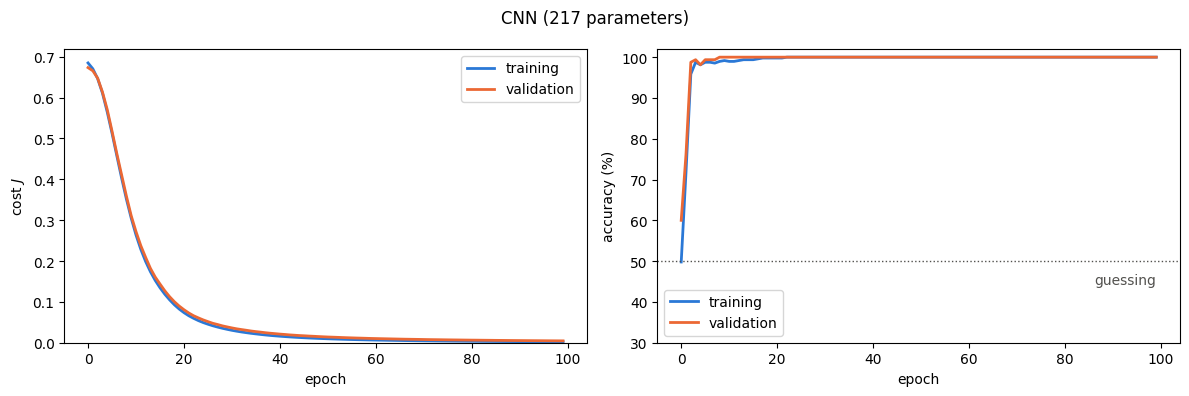

In [15]:
optimiser = torch.optim.Adam(cnn.parameters(), lr=0.002)
# TODO: fill in train_model footprint to train the model with 100 epochs
J_train, J_val, acc_train, acc_val = train_model(cnn, optimiser, nn.BCELoss(), n_epochs=100)

print(f"final training cost {J_train[-1]:.3f},  final validation cost {J_val[-1]:.3f}")
print(f"final training accuracy {acc_train[-1]:.3f},  final validation accuracy {acc_val[-1]:.3f}")
plot_curves(J_train, J_val, acc_train, acc_val, f"CNN ({count_parameters(cnn)} parameters)")

### Your evaluation 6

*How do these curves compare with the MLP's? Is there any sign of overfitting?*

...
The CNN curves are very different. Training and validation cost fall together, smoothly, to about 0.002 and 0.005, and both accuracies reach 100% within about 20 epochs. The two curves lie almost on top of each other, so there is no sign of overfitting. The model learns the shape of the marks, so it generalises to the unseen validation images. This is the opposite of the MLP, where the training and validation curves split apart almost immediately.

---
## 7. Comparing the MLP and the CNN

Finally, the test set: 160 images neither network has seen.

### Example 7

In [16]:
print(f"{'':6s}{'parameters':>12s}{'training acc.':>16s}{'test acc.':>12s}")
for name, model in [("MLP", mlp), ("CNN", cnn)]:
    print(f"{name:6s}{count_parameters(model):12,d}{accuracy(model, X_train_t, y_train_t):16.3f}{accuracy(model, X_test_t, y_test_t):12.3f}")

        parameters   training acc.   test acc.
MLP         41,153           1.000       0.494
CNN            217           1.000       1.000


### Your evaluation 7

*The CNN has about 200 times fewer parameters than the MLP. Why does it do so much better? What does a CNN "know" about images that an MLP does not?*

...

The CNN does much better because it has the right assumption built in as a mark looks the same wherever it appears. Each filter is one small neuron with 25 weights that is applied at every position, so what it learns about an x is learned once and used everywhere. Global max pooling then keeps only the strongest response, so the output depends on whether a mark is present and not on where it is. The MLP knows nothing about neighbouring pixels or positions and treats the image as 576 unrelated numbers. That is why the CNN gets 100% test accuracy with 217 parameters, while the MLP with 41,153 parameters gets 49.4%, which is chance.

---
## 8. What did the CNN learn?

The CNN's knowledge is in its 8 filters. Each filter is just 25 weights, so we can draw it as a 5 × 5 image: red for positive weights, blue for negative. Above each filter is the weight connecting it to the output neuron: positive means "this filter is saying yes, I have evidence for '×'", negative means evidence for '+'.

### Example 8

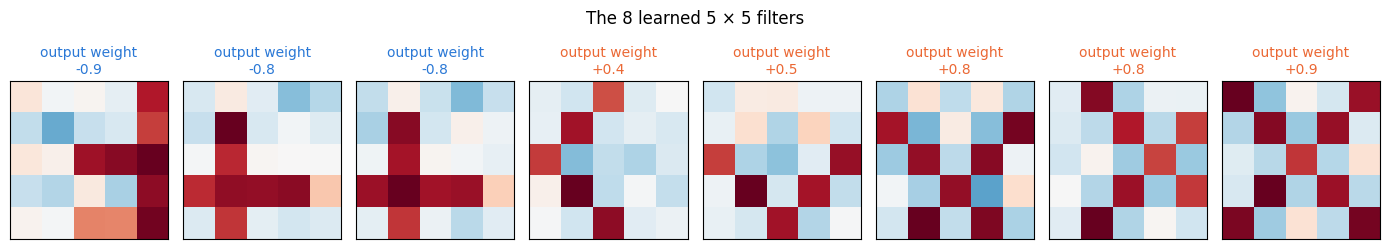

In [17]:
filters = cnn[0].weight.detach().numpy()          # shape (8, 1, 5, 5)
out_w = cnn[4].weight.detach().numpy()[0]         # shape (8,): output-layer weight for each filter
order = np.argsort(out_w)                         # most '+'-like first, most 'x'-like last

fig, axs = plt.subplots(1, 8, figsize=(14, 2.8))
for ax, f in zip(axs, order):
    v = np.abs(filters[f, 0]).max()
    ax.imshow(filters[f, 0], cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(f"output weight\n{out_w[f]:+.1f}", color=ORANGE if out_w[f] > 0 else BLUE, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("The 8 learned 5 × 5 filters"); plt.tight_layout(); plt.show()

### Your evaluation 8

*Do any filters look like a '+' or a '×'? Do the filters with positive output weights look different from those with negative ones? Are any of the 8 filters very similar to each other?*

...